# 04 V2 — ML Baselines | 60 Expanded Features | CIC-IDS2017

**NIDS-SE-AT-CNN · Kaggle · Protocol mới từ Notebook 03B**

Mục tiêu: huấn luyện **Random Forest, XGBoost, LightGBM** trên **đúng split `train/val/test`** và bộ features được chọn bằng **validation** trong 03B. Xuất artifact để Notebook 05 V6 sử dụng cùng protocol.

**Nguyên tắc:** Không resample, không chia lại, không dùng metadata làm feature. Imputer được fit trên train; validation được dùng để chọn mô hình; test chỉ dùng **một lần sau khi cấu hình/feature đã chốt**, tránh tuning theo test. CSV gốc thiếu IP/timestamp nên **chưa phải benchmark độc lập theo host/thời gian**. Các lớp cực hiếm không được chứng minh là ổn định. Điểm số protocol mới **không được so trực tiếp** với V1–V5.

> **Kaggle:** Save Version notebook 03B, rồi Add Input → output của notebook 03B; file cần có `cic_expanded_splits.parquet`, `feature_sets.json`, `experiment_manifest.json`. Không dùng lại `cic_pilot_splits.parquet` (19 features).

## 1. Cấu hình và tìm chính xác bộ dữ liệu 03B

In [91]:
from pathlib import Path
import json, hashlib, time, os, warnings
import numpy as np
import pandas as pd

SEED = 42
THREADS = 4
# Đặt chính xác thư mục output Notebook 03B nếu Kaggle báo thấy nhiều bản.
INPUT_DIR = None  # ví dụ: Path('/kaggle/input/03b-cic-preprocessing-fe')
OUTPUT = Path('/kaggle/working/nids_outputs/04_ML_Baselines_V2_Expanded') if Path('/kaggle/working').exists() else Path('reports/notebook_outputs/04_ML_Baselines_V2_Expanded')
OUTPUT.mkdir(parents=True, exist_ok=True)

if INPUT_DIR is not None:
    candidate_dirs = [Path(INPUT_DIR)]
else:
    roots = [Path('/kaggle/working/nids_outputs/03B_CIC_Feature_Engineering'), Path('/kaggle/input')]
    candidate_dirs = [roots[0]] if (roots[0] / 'cic_expanded_splits.parquet').exists() else []
    if not candidate_dirs and roots[1].exists():
        candidate_dirs = sorted(set(p.parent for p in roots[1].rglob('cic_expanded_splits.parquet')))
valid_dirs = [p for p in candidate_dirs if all((p / file).is_file() for file in ['cic_expanded_splits.parquet','feature_sets.json','experiment_manifest.json'])]
if len(valid_dirs) != 1:
    raise FileNotFoundError(f'Cần đúng một thư mục output 03B đầy đủ, tìm thấy: {valid_dirs}. Hãy Save Version 03B và Add Input; nếu nhiều bản hãy đặt INPUT_DIR.')
input_dir = valid_dirs[0]
split_path = input_dir / 'cic_expanded_splits.parquet'
feature_sets = json.loads((input_dir / 'feature_sets.json').read_text(encoding='utf-8'))
source_manifest = json.loads((input_dir / 'experiment_manifest.json').read_text(encoding='utf-8'))
print('Source 03B:', input_dir)
print('Rows in 03B manifest:',source_manifest.get('sample_rows'))
print('Validation feature choice:',source_manifest.get('validation_selected_feature_set'))
print('Output:', OUTPUT)

Source 03B: /kaggle/working/nids_outputs/03B_CIC_Feature_Engineering
Rows in 03B manifest: 39193
Validation feature choice: with_port
Output: /kaggle/working/nids_outputs/04_ML_Baselines_V2_Expanded


## 2. Kiểm tra schema, nhãn, split và nhóm trùng lặp — không chia lại

In [92]:
from sklearn.preprocessing import LabelEncoder

sample = pd.read_parquet(split_path)
required = {'Label','_split','_binary_label','_source_file','_source_row','_duplicate_group'}
if not required.issubset(sample.columns):
    raise ValueError(f'Thiếu trường từ notebook 03B: {sorted(required - set(sample.columns))}')
if sample['_split'].isna().any() or not set(sample['_split'].astype(str).unique()) == {'train','val','test'}:
    raise ValueError('Split phải có đúng các nhãn train, val, test')
if len(sample) != int(source_manifest['sample_rows']):
    raise ValueError('Số dòng không khớp manifest 03B')
if sample.groupby('_duplicate_group')['_split'].nunique().max() != 1:
    raise ValueError('EXACT-DUPLICATE LEAKAGE: một nhóm trùng feature xuất hiện ở nhiều splits')
if sample.duplicated(['_source_file','_source_row']).any():
    raise ValueError('Trùng row origin')
if not np.array_equal(sample['_binary_label'].astype(int).to_numpy(), (sample['Label'].astype(str) != 'BENIGN').astype(int).to_numpy()):
    raise ValueError('Binary label và Label không nhất quán')

feature_variant = source_manifest.get('validation_selected_feature_set', 'with_port')
if feature_variant not in feature_sets:
    raise ValueError(f'Manifest chọn {feature_variant}, feature_sets chỉ có {list(feature_sets)}')
features = feature_sets[feature_variant]
if not features or len(features) != len(set(features)) or not set(features).issubset(sample.columns):
    raise ValueError('Danh sách feature không hợp lệ hoặc thiếu cột')
if any(f.startswith('_') or f == 'Label' for f in features):
    raise ValueError('Feature đang chứa metadata/target')

split = sample['_split'].astype(str)
train_idx, val_idx, test_idx = [(split == name).to_numpy() for name in ['train','val','test']]
encoder = LabelEncoder().fit(sample.loc[train_idx, 'Label'].astype(str))
if not set(sample['Label'].astype(str)).issubset(encoder.classes_):
    raise ValueError('Val/test chứa nhãn không xuất hiện trong train')
y = encoder.transform(sample['Label'].astype(str))
all_ids = np.arange(len(encoder.classes_))
benign_id = int(encoder.transform(['BENIGN'])[0])
X = sample[features].apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf],np.nan).astype('float32')
if X.notna().sum().sum() == 0: raise ValueError('Tất cả giá trị feature không hợp lệ')
for name, mask in [('train',train_idx),('val',val_idx),('test',test_idx)]:
    print(f'{name}: {mask.sum()} samples, {len(np.unique(y[mask]))} labels')
print('Feature variant:',feature_variant,'Feature count:',len(features))
print('Class names:',list(encoder.classes_))
assert train_idx.sum() and val_idx.sum() and test_idx.sum()
assert sum((train_idx,val_idx,test_idx)).max()==1
support = pd.crosstab(sample['Label'],sample['_split']).reindex(columns=['train','val','test'],fill_value=0)
support.to_csv(OUTPUT/'class_support.csv')
display(support)
(OUTPUT/'feature_names.json').write_text(json.dumps(features,ensure_ascii=False,indent=2),encoding='utf-8')
(OUTPUT/'class_names.json').write_text(json.dumps(encoder.classes_.tolist(),ensure_ascii=False,indent=2),encoding='utf-8')

train: 23922 samples, 15 labels
val: 7862 samples, 15 labels
test: 7409 samples, 15 labels
Feature variant: with_port Feature count: 60
Class names: ['BENIGN', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'PortScan', 'SSH-Patator', 'Web Attack ï¿½ Brute Force', 'Web Attack ï¿½ Sql Injection', 'Web Attack ï¿½ XSS']


_split,train,val,test
Label,,,
BENIGN,4279,1368,1353
Bot,1190,389,387
DDoS,2107,712,681
DoS GoldenEye,2096,723,681
DoS Hulk,2136,779,585
DoS Slowhttptest,2186,687,627
DoS slowloris,2077,724,699
FTP-Patator,2259,683,558
Heartbleed,8,1,2


279

## 3. Mô hình cố định và preprocessing train-only

Cấu hình baseline **định trước** nhằm có mốc so sánh. Nếu muốn thêm tuning sau này, phải dùng validation và giữ test ngoài vòng chọn hyperparameter. Cả ba mô hình dùng đúng features và split.

In [93]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

configs = {
    'RandomForest': RandomForestClassifier(
        n_estimators=240, min_samples_leaf=2, class_weight='balanced_subsample',
        n_jobs=THREADS, random_state=SEED),
    'XGBoost': XGBClassifier(
        n_estimators=320, max_depth=6, learning_rate=0.06, subsample=0.9,
        colsample_bytree=0.9, reg_lambda=2.0, tree_method='hist',
        eval_metric='mlogloss', n_jobs=THREADS, random_state=SEED),
    'LightGBM': LGBMClassifier(
        objective='multiclass', n_estimators=360, learning_rate=0.045,
        num_leaves=23, max_depth=8, min_child_samples=35,
        reg_lambda=2.0, colsample_bytree=0.9, subsample=0.9, subsample_freq=1,
        n_jobs=THREADS, random_state=SEED, verbosity=-1),
}
model_pipelines={name:Pipeline([('imputer',SimpleImputer(strategy='median')),('classifier',est)]) for name,est in configs.items()}
print({name:est.get_params() for name,est in configs.items()})

{'RandomForest': {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced_subsample', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 240, 'n_jobs': 4, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}, 'XGBoost': {'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.9, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.06, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 6,

## 4. Huấn luyện ba baseline; đánh giá TRAIN và VALIDATION trước

In [94]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, classification_report

def evaluate(y_true, y_pred):
    true_attack = (np.asarray(y_true) != benign_id)
    pred_attack = (np.asarray(y_pred) != benign_id)
    benign_count = int((~true_attack).sum())
    fp = int(((~true_attack) & pred_attack).sum())
    return {
        'accuracy': float(accuracy_score(y_true,y_pred)),
        'macro_f1': float(f1_score(y_true,y_pred,labels=all_ids,average='macro',zero_division=0)),
        'weighted_f1': float(f1_score(y_true,y_pred,labels=all_ids,average='weighted',zero_division=0)),
        'attack_precision': float(precision_score(true_attack,pred_attack,zero_division=0)),
        'attack_recall': float(recall_score(true_attack,pred_attack,zero_division=0)),
        'attack_f1': float(f1_score(true_attack,pred_attack,zero_division=0)),
        'fpr': fp/benign_count if benign_count else float('nan'),
        'false_positives': fp, 'benign_support': benign_count,
    }

validation_rows=[]
training_seconds={}
for name, pipeline in model_pipelines.items():
    t0=time.perf_counter()
    pipeline.fit(X.loc[train_idx],y[train_idx])
    training_seconds[name]=round(time.perf_counter()-t0,3)
    joblib.dump(pipeline,OUTPUT/f'{name}_pipeline.joblib',compress=3)
    for part, mask in [('train',train_idx),('val',val_idx)]:
        pred = pipeline.predict(X.loc[mask]).astype(int)
        row={'model':name,'split':part,'samples':int(mask.sum()),'train_seconds':training_seconds[name],**evaluate(y[mask],pred)}
        validation_rows.append(row)
        report=classification_report(y[mask],pred,labels=all_ids,target_names=encoder.classes_,output_dict=True,zero_division=0)
        (OUTPUT/f'{name}_{part}_classification_report.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
        if part=='val':
            pd.DataFrame({'row_index':np.flatnonzero(mask),'true_label':encoder.inverse_transform(y[mask]),'pred_label':encoder.inverse_transform(pred),
                          'source_file':sample.loc[mask,'_source_file'].to_numpy(),'source_row':sample.loc[mask,'_source_row'].to_numpy()}).to_csv(OUTPUT/f'{name}_val_predictions.csv',index=False)
            np.save(OUTPUT/f'{name}_val_confusion_matrix.npy',confusion_matrix(y[mask],pred,labels=all_ids))
    print(name,'time:',training_seconds[name],'sec | val Macro-F1:',validation_rows[-1]['macro_f1'])

validation_df=pd.DataFrame(validation_rows)
validation_df.to_csv(OUTPUT/'train_validation_metrics.csv',index=False)
val_table=validation_df[validation_df.split=='val'].sort_values(['macro_f1','accuracy'],ascending=False)
display(val_table[['model','accuracy','macro_f1','weighted_f1','attack_recall','fpr','train_seconds']].round(4))

RandomForest time: 6.583 sec | val Macro-F1: 0.8712457824924302
XGBoost time: 17.744 sec | val Macro-F1: 0.8742674377847381


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM time: 13.553 sec | val Macro-F1: 0.8757837616556314


,model,accuracy,macro_f1,weighted_f1,attack_recall,fpr,train_seconds
5,LightGBM,0.9805,0.8758,0.9792,0.9994,0.0051,13.553
3,XGBoost,0.9799,0.8743,0.9788,0.9995,0.0051,17.744
1,RandomForest,0.9780,0.8712,0.9778,0.9991,0.0117,6.583


## 5. Chọn mô hình bằng VALIDATION và chốt thí nghiệm trước TEST

In [95]:
selected_model=val_table.iloc[0]['model']
selection_record={
    'model_selection_split':'val',
    'criterion':'max val macro_f1, tie-break val accuracy',
    'selected_model':selected_model,
    'selected_feature_variant':feature_variant,
    'number_of_features':len(features),
    'validation_results':val_table.to_dict(orient='records'),
    'comment':'Decision recorded before TEST evaluation; not to be retuned using test outcomes.'
}
(OUTPUT/'validation_selection.json').write_text(json.dumps(selection_record,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('SELECTED BY VALIDATION ONLY:',selected_model)
print('DO NOT EDIT THIS CELL AFTER SEEING TEST RESULTS TO CHASE TEST METRICS')

SELECTED BY VALIDATION ONLY: LightGBM
DO NOT EDIT THIS CELL AFTER SEEING TEST RESULTS TO CHASE TEST METRICS


## 6. Đánh giá TEST (một lần, sau khi lựa chọn)

Test vẫn thuộc cùng bộ capture, kết quả **exploratory**. Không tối ưu các mô hình tiếp dựa trên kết quả test này.

In [96]:
test_rows=[]
per_class_rows=[]
for name,pipeline in model_pipelines.items():
    test_pred=pipeline.predict(X.loc[test_idx]).astype(int)
    row={'model':name,'split':'test','samples':int(test_idx.sum()),'train_seconds':training_seconds[name],**evaluate(y[test_idx],test_pred)}
    test_rows.append(row)
    report=classification_report(y[test_idx],test_pred,labels=all_ids,target_names=encoder.classes_,output_dict=True,zero_division=0)
    (OUTPUT/f'{name}_test_classification_report.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    cm=confusion_matrix(y[test_idx],test_pred,labels=all_ids)
    np.save(OUTPUT/f'{name}_test_confusion_matrix.npy',cm)
    pd.DataFrame({'row_index':np.flatnonzero(test_idx),'true_label':encoder.inverse_transform(y[test_idx]),'pred_label':encoder.inverse_transform(test_pred),
                  'source_file':sample.loc[test_idx,'_source_file'].to_numpy(),'source_row':sample.loc[test_idx,'_source_row'].to_numpy()}).to_csv(OUTPUT/f'{name}_test_predictions.csv',index=False)
    for idx,label in enumerate(encoder.classes_):
        d=report[str(label)]
        per_class_rows.append({'model':name,'class':label,'support':int(d['support']),'precision':d['precision'],'recall':d['recall'],'f1':d['f1-score']})

metrics=pd.concat([validation_df,pd.DataFrame(test_rows)],ignore_index=True)
metrics.to_csv(OUTPUT/'baseline_metrics_all_splits.csv',index=False)
test_table=pd.DataFrame(test_rows).sort_values('macro_f1',ascending=False)
test_table.to_csv(OUTPUT/'baseline_test_metrics.csv',index=False)
per_class=pd.DataFrame(per_class_rows)
per_class.to_csv(OUTPUT/'baseline_test_per_class.csv',index=False)
print('Selected model on validation:',selected_model)
display(test_table[['model','accuracy','macro_f1','weighted_f1','attack_precision','attack_recall','fpr']].round(4))
display(per_class[per_class['class'].str.contains('Web Attack|BENIGN|Bot',regex=True)].sort_values(['class','model']).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Selected model on validation: LightGBM


,model,accuracy,macro_f1,weighted_f1,attack_precision,attack_recall,fpr
2,LightGBM,0.9785,0.9064,0.9776,0.9987,0.9992,0.0059
1,XGBoost,0.9789,0.9002,0.9779,0.9987,0.9992,0.0059
0,RandomForest,0.9737,0.8380,0.9735,0.9959,0.9979,0.0185


,model,class,support,precision,recall,f1
30,LightGBM,BENIGN,1353,0.9963,0.9941,0.9952
0,RandomForest,BENIGN,1353,0.9903,0.9815,0.9859
15,XGBoost,BENIGN,1353,0.9963,0.9941,0.9952
31,LightGBM,Bot,387,0.9822,1.0000,0.9910
1,RandomForest,Bot,387,0.9651,1.0000,0.9822
16,XGBoost,Bot,387,0.9822,1.0000,0.9910
42,LightGBM,Web Attack ï¿½ Brute Force,293,0.7409,0.8294,0.7826
12,RandomForest,Web Attack ï¿½ Brute Force,293,0.7318,0.7543,0.7429
27,XGBoost,Web Attack ï¿½ Brute Force,293,0.7373,0.8430,0.7866
43,LightGBM,Web Attack ï¿½ Sql Injection,3,1.0000,0.3333,0.5000


## 7. Confusion matrix, cặp nhãn nhầm và feature importance

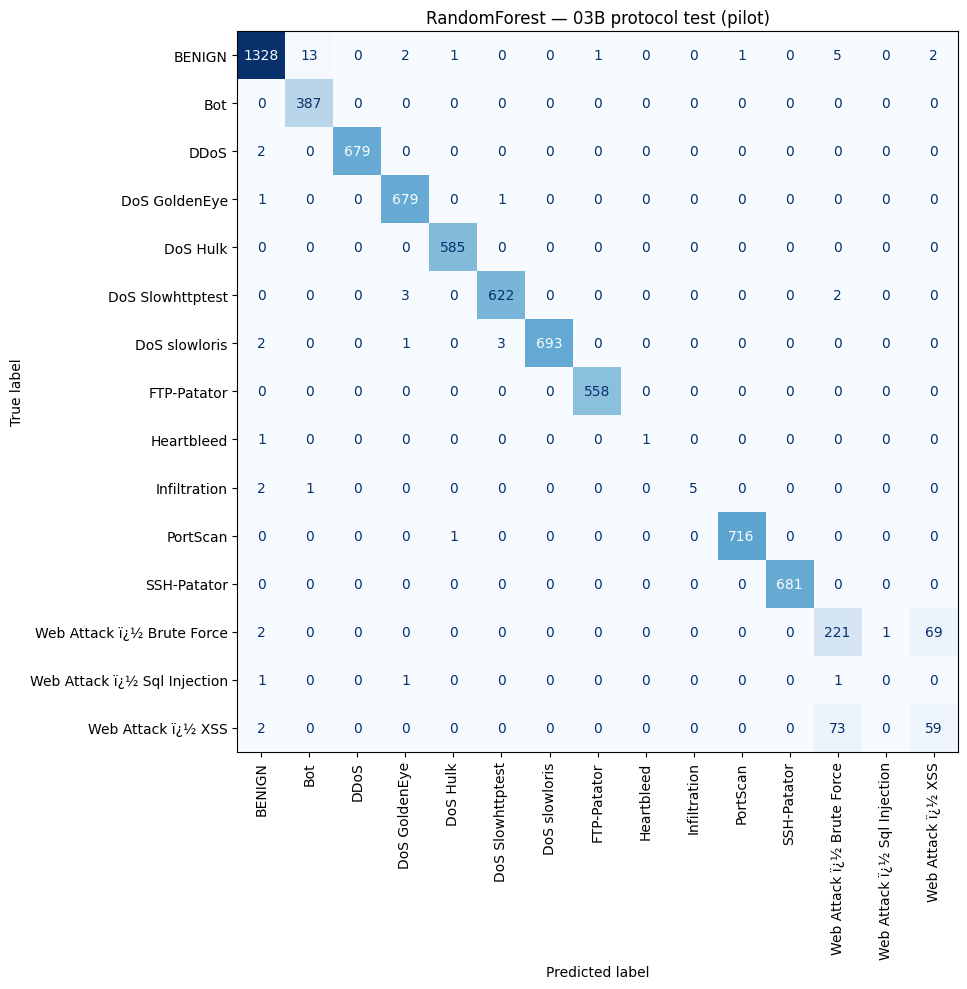

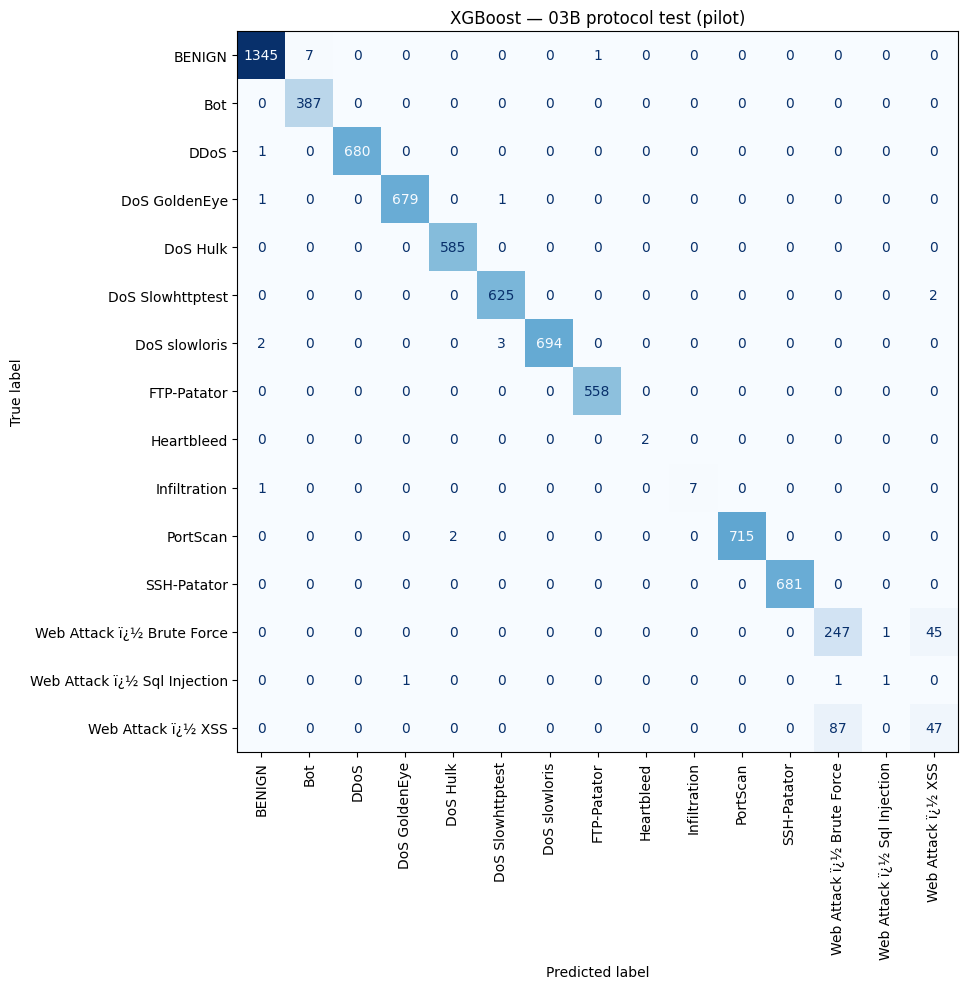

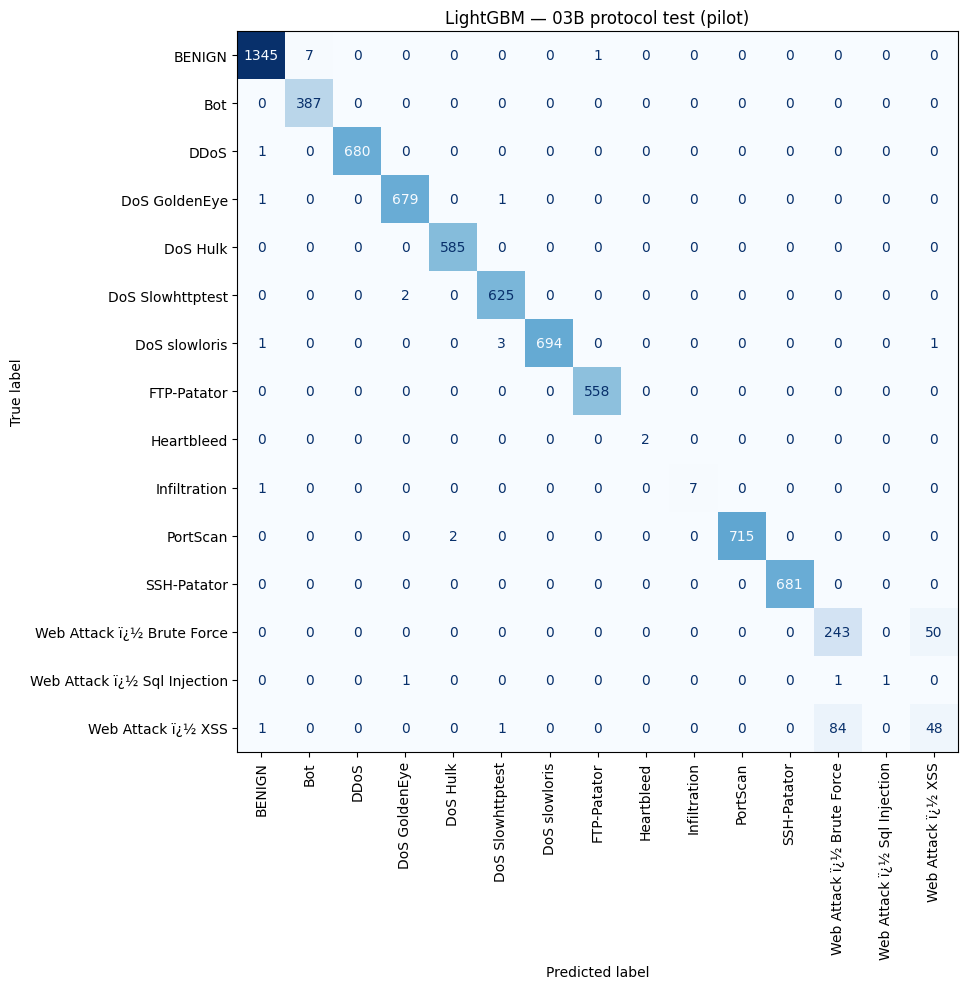

Selected model top confusions:


,true_label,pred_label,count
16,Web Attack ï¿½ XSS,Web Attack ï¿½ Brute Force,84
11,Web Attack ï¿½ Brute Force,Web Attack ï¿½ XSS,50
0,BENIGN,Bot,7
7,DoS slowloris,DoS Slowhttptest,3
5,DoS Slowhttptest,DoS GoldenEye,2
10,PortScan,DoS Hulk,2
4,DoS GoldenEye,DoS Slowhttptest,1
1,BENIGN,FTP-Patator,1
2,DDoS,BENIGN,1
8,DoS slowloris,Web Attack ï¿½ XSS,1


,feature,importance
19,Flow IAT Min,8273
24,Fwd IAT Min,6853
48,Init_Win_bytes_forward,6122
0,Destination Port,5598
49,Init_Win_bytes_backward,4076
34,Bwd Packets/s,3064
1,Flow Duration,2650
16,Flow IAT Mean,2021
20,Fwd IAT Total,1967
18,Flow IAT Max,1754


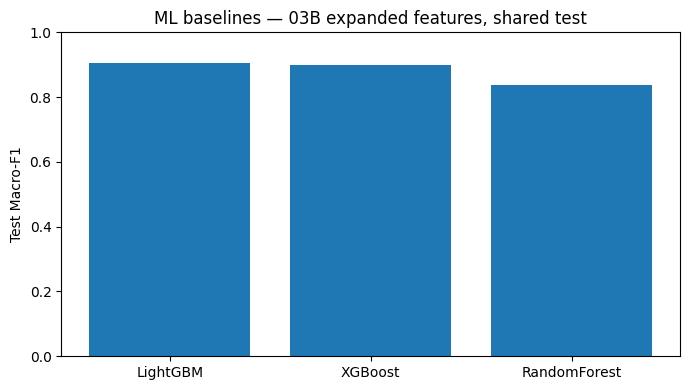

In [97]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for name, pipeline in model_pipelines.items():
    cm=np.load(OUTPUT/f'{name}_test_confusion_matrix.npy')
    fig,ax=plt.subplots(figsize=(12,10))
    ConfusionMatrixDisplay(cm,display_labels=encoder.classes_).plot(ax=ax,xticks_rotation=90,cmap='Blues',colorbar=False,values_format='d')
    ax.set_title(f'{name} — 03B protocol test (pilot)')
    fig.tight_layout();fig.savefig(OUTPUT/f'{name}_test_confusion_matrix.png',dpi=140,bbox_inches='tight');plt.show();plt.close(fig)

    mis=pd.read_csv(OUTPUT/f'{name}_test_predictions.csv')
    confusion_pairs=(mis.loc[mis.true_label!=mis.pred_label].groupby(['true_label','pred_label']).size()
                        .reset_index(name='count').sort_values('count',ascending=False))
    confusion_pairs.to_csv(OUTPUT/f'{name}_test_top_confusions.csv',index=False)
    if name==selected_model:
        print('Selected model top confusions:');display(confusion_pairs.head(20))

    est=pipeline.named_steps['classifier']
    if hasattr(est,'feature_importances_'):
        fi=pd.DataFrame({'feature':features,'importance':est.feature_importances_}).sort_values('importance',ascending=False)
        fi.to_csv(OUTPUT/f'{name}_feature_importance.csv',index=False)
        if name==selected_model:
            display(fi.head(20))

fig,ax=plt.subplots(figsize=(7,4))
ax.bar(test_table['model'],test_table['macro_f1'])
ax.set_ylim(0,1);ax.set_ylabel('Test Macro-F1');ax.set_title('ML baselines — 03B expanded features, shared test')
fig.tight_layout();fig.savefig(OUTPUT/'baseline_test_macro_f1.png',dpi=160);plt.show();plt.close(fig)

## 8. Lưu manifest để Notebook 05 V6 / 09 sử dụng

In [98]:
def sha256_file(path,chunk_size=4*1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk: break
            h.update(chunk)
    return h.hexdigest()

manifest={
    'experiment':'04_ML_Baselines_V2_Expanded',
    'dataset':'CIC-IDS2017',
    'protocol':source_manifest['protocol'],
    'split_source':str(split_path),
    'split_sha256':sha256_file(split_path),
    'seed':SEED,'rows':len(sample),
    'feature_variant':feature_variant,
    'feature_names':features,
    'class_names':encoder.classes_.tolist(),
    'split_counts':{k:int(v) for k,v in split.value_counts().to_dict().items()},
    'chosen_model_by_validation':selected_model,
    'validation_selection_metric':'macro_f1 (15-class)',
    'model_params':{name:est.get_params() for name,est in configs.items()},
    'limitations':[
       'Test split is from same original CIC captures (no session/host/time-disjoint holdout)',
       'StratifiedGroupKFold prevents exact feature duplicate split overlap, not near-duplicate/event leakage',
       'Pilot class prevalences differ from deployment conditions, so FPR/precision need external validation',
       'Rare class support (Heartbleed, SQL Injection, Infiltration) is extremely small',
       'Do not compare numerically to Notebook 04 V1 or Notebook 05 V1-V5 which use a different split'
    ]
}
(OUTPUT/'experiment_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('Output folder:',OUTPUT)
print('Artifacts:',len(list(OUTPUT.iterdir())))
for path in sorted(OUTPUT.iterdir()): print(' -',path.name)
print('SAVE VERSION to make notebook outputs available to 05 V6')

Output folder: /kaggle/working/nids_outputs/04_ML_Baselines_V2_Expanded
Artifacts: 43
 - LightGBM_feature_importance.csv
 - LightGBM_pipeline.joblib
 - LightGBM_test_classification_report.json
 - LightGBM_test_confusion_matrix.npy
 - LightGBM_test_confusion_matrix.png
 - LightGBM_test_predictions.csv
 - LightGBM_test_top_confusions.csv
 - LightGBM_train_classification_report.json
 - LightGBM_val_classification_report.json
 - LightGBM_val_confusion_matrix.npy
 - LightGBM_val_predictions.csv
 - RandomForest_feature_importance.csv
 - RandomForest_pipeline.joblib
 - RandomForest_test_classification_report.json
 - RandomForest_test_confusion_matrix.npy
 - RandomForest_test_confusion_matrix.png
 - RandomForest_test_predictions.csv
 - RandomForest_test_top_confusions.csv
 - RandomForest_train_classification_report.json
 - RandomForest_val_classification_report.json
 - RandomForest_val_confusion_matrix.npy
 - RandomForest_val_predictions.csv
 - XGBoost_feature_importance.csv
 - XGBoost_pipelin